# Kaggle Playground S6E11 — Predicting Credit Card Fraud
Metric: ROC AUC. Target: `is_fraud` (~1.7% positive).

Run cells top to bottom with **Shift+Enter**.

## 1. Load data

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import lightgbm as lgb

DATA = "data"
train = pd.read_csv(f"{DATA}/train.csv")
test  = pd.read_csv(f"{DATA}/test.csv")
sub   = pd.read_csv(f"{DATA}/sample_submission.csv")
TARGET = "is_fraud"
print(train.shape, test.shape)
train.head()

(699960, 26) (299984, 25)


,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


## 2. Quick EDA

In [2]:
print(train[TARGET].value_counts(normalize=True))
print(train.isna().sum()[train.isna().sum() > 0])
train.describe().T

is_fraud
0.0    0.9833
1.0    0.0167
Name: proportion, dtype: float64
Series([], dtype: int64)


,count,mean,std,min,25%,50%,75%,max
id,699960.0,349979.500000,202061.191549,0.00,174989.75,349979.50,524969.25,699959.00
amount_usd,699960.0,79.893068,205.173538,1.00,15.81,27.25,43.11,6872.69
hours_since_last_txn,699960.0,6.633734,6.290133,0.01,2.11,4.73,9.19,51.98
txn_count_last_24h,699960.0,2.984092,1.498998,0.00,2.00,3.00,4.00,11.00
distance_from_home_km,699960.0,13.587575,11.617325,0.00,4.43,10.22,19.75,57.93
card_age_months,699960.0,46.862982,5.579190,25.00,43.00,47.00,51.00,73.00
customer_age,699960.0,51.430286,17.899150,18.00,38.00,52.00,66.00,81.00
account_balance_usd,699960.0,2064.998070,3400.132922,58.25,834.12,1382.74,2517.02,99701.39
cvv_retry_count,699960.0,0.085472,0.289524,0.00,0.00,0.00,0.00,3.00
velocity_score,699960.0,18.929445,10.864385,0.00,11.40,18.60,26.00,72.90


In [6]:
cat_cols = [c for c in train.columns if c not in ["id", TARGET]
            and not pd.api.types.is_numeric_dtype(train[c]) and not pd.api.types.is_bool_dtype(train[c])]
num_cols = [c for c in train.columns if c not in cat_cols + ["id", TARGET]]
print("categorical:", cat_cols)
# Fraud rate by category
for c in cat_cols:
    print(train.groupby(c)[TARGET].agg(["mean", "count"]).sort_values("mean", ascending=False), "\n")

categorical: ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']
                       mean   count
merchant_category                  
Gift Cards         0.072970    9456
Crypto Exchange    0.065279    5285
Gaming             0.055121   23784
Electronics        0.030826   48693
Streaming          0.022481   47196
Travel             0.018597   28715
Utilities          0.013824   42027
Healthcare         0.012873   35889
Fuel               0.012375   59880
Restaurants        0.011434  101360
Groceries          0.011117  142578
Online Retail      0.011083  155097 

                mean   count
card_type                   
Amex        0.019019   45797
Visa        0.016985  345001
RuPay       0.016806   37070
Mastercard  0.016025  254857
Discover    0.014563   17235 

                       mean   count
auth_method                        
No Authentication  0.064450   67060
3D Secure          0.014750  210036
OTP                0.014066  175178
PIN                0

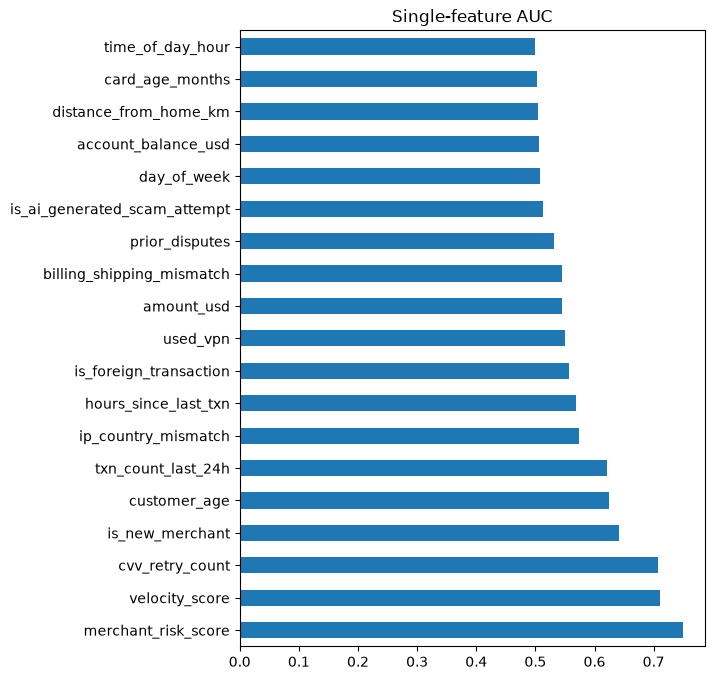

In [7]:
# Which numeric features separate fraud vs. not? (single-feature AUC)
aucs = {c: roc_auc_score(train[TARGET], train[c].fillna(-999)) for c in num_cols}
pd.Series(aucs).sub(0.5).abs().sort_values(ascending=False).add(0.5).plot.barh(figsize=(6, 8))
plt.title("Single-feature AUC"); plt.show()

## 3. Prepare features

In [8]:
def prep(df):
    df = df.copy()
    for c in cat_cols:
        df[c] = df[c].astype("category")
    # --- feature engineering ideas (add one at a time, check CV) ---
    # df["amt_to_balance"] = df["amount_usd"] / (df["account_balance_usd"] + 1)
    # df["log_amount"] = np.log1p(df["amount_usd"])
    return df

X = prep(train.drop(columns=["id", TARGET]))
y = train[TARGET]
X_test = prep(test.drop(columns=["id"]))
# keep test categories aligned with train
for c in cat_cols:
    X_test[c] = pd.Categorical(X_test[c], categories=X[c].cat.categories)

## 4. Baseline: 5-fold LightGBM
The CV AUC printed here is your *local* score — trust it more than the public leaderboard.

In [9]:
params = dict(objective="binary", metric="auc", learning_rate=0.05, num_leaves=63,
              min_child_samples=50, feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1,
              n_estimators=5000, verbose=-1)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof = np.zeros(len(X)); pred_lgb = np.zeros(len(X_test))
for fold, (tr, va) in enumerate(skf.split(X, y)):
    m = lgb.LGBMClassifier(**params)
    m.fit(X.iloc[tr], y.iloc[tr], eval_set=[(X.iloc[va], y.iloc[va])],
          callbacks=[lgb.early_stopping(200, verbose=False)])
    oof[va] = m.predict_proba(X.iloc[va])[:, 1]
    pred_lgb += m.predict_proba(X_test)[:, 1] / 5
    print(f"fold {fold}: AUC {roc_auc_score(y.iloc[va], oof[va]):.5f}  (trees {m.best_iteration_})")
print(f"CV AUC: {roc_auc_score(y, oof):.5f}")
oof_lgb = oof.copy()

c:\Users\JCK\Documents\python project\kaggle-fraud\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


fold 0: AUC 0.94330  (trees 235)


c:\Users\JCK\Documents\python project\kaggle-fraud\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


fold 1: AUC 0.94662  (trees 184)


c:\Users\JCK\Documents\python project\kaggle-fraud\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


fold 2: AUC 0.94995  (trees 159)


c:\Users\JCK\Documents\python project\kaggle-fraud\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


fold 3: AUC 0.94579  (trees 153)


c:\Users\JCK\Documents\python project\kaggle-fraud\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


fold 4: AUC 0.94064  (trees 326)
CV AUC: 0.94499


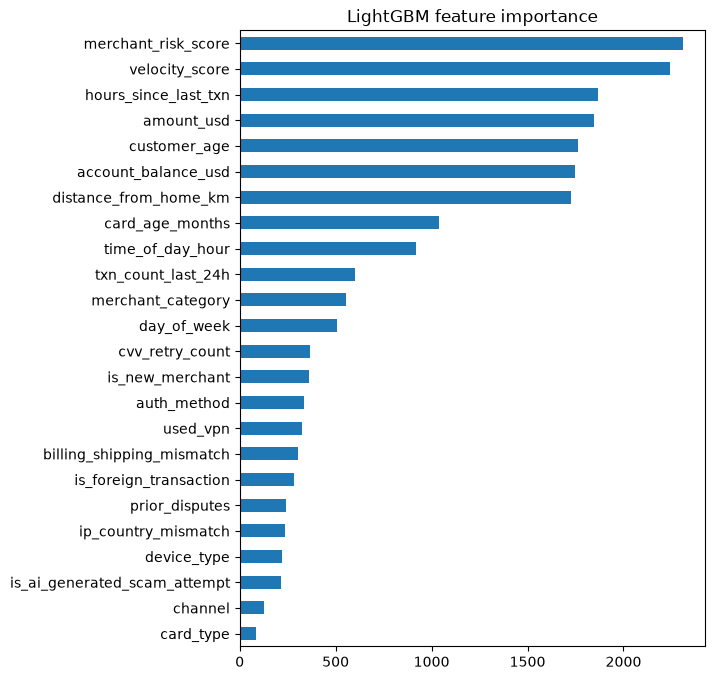

In [10]:
imp = pd.Series(m.feature_importances_, index=X.columns).sort_values()
imp.plot.barh(figsize=(6, 8)); plt.title("LightGBM feature importance"); plt.show()

## 5. Write submission

In [11]:
sub[TARGET] = pred_lgb
sub.to_csv("submission.csv", index=False)
sub.head()

,id,is_fraud
0,699960,0.000360
1,699961,0.000280
2,699962,0.095581
3,699963,0.001461
4,699964,0.001590


Submit from the VS Code terminal:
```
kaggle competitions submit -c playground-series-s6e11 -f submission.csv -m "lgb baseline"
```

## 6. Next: more models + blend
Train XGBoost / CatBoost with the same folds, save their OOF and test preds, then blend. Rank-averaging works well for AUC.

In [ ]:
# from scipy.stats import rankdata
# def rank(p): return rankdata(p) / len(p)
# Example once you have oof_xgb / pred_xgb etc.:
# blend_oof = 0.5*rank(oof_lgb) + 0.5*rank(oof_xgb)
# print(roc_auc_score(y, blend_oof))
# sub[TARGET] = 0.5*rank(pred_lgb) + 0.5*rank(pred_xgb)

In [12]:
import os
os.makedirs("preds", exist_ok=True)
np.save("preds/oof_lgb.npy", oof_lgb); np.save("preds/test_lgb.npy", pred_lgb)

bool_cols = X.select_dtypes("bool").columns
def to_int_bools(df):
    df = df.copy(); df[bool_cols] = df[bool_cols].astype(int); return df

In [ ]:
import xgboost as xgb
Xx, Xx_test = to_int_bools(X), to_int_bools(X_test)

oof_xgb = np.zeros(len(X)); pred_xgb = np.zeros(len(X_test))
for fold, (tr, va) in enumerate(skf.split(Xx, y)):
    m = xgb.XGBClassifier(n_estimators=5000, learning_rate=0.03, max_depth=6, min_child_weight=5,
                          subsample=0.8, colsample_bytree=0.7, reg_lambda=1.0,
                          tree_method="hist", device="cuda",enable_categorical=True, max_cat_to_onehot=1,
                          eval_metric="auc", early_stopping_rounds=200, n_jobs=-1)
    m.fit(Xx.iloc[tr], y.iloc[tr], eval_set=[(Xx.iloc[va], y.iloc[va])], verbose=False)
    oof_xgb[va] = m.predict_proba(Xx.iloc[va])[:, 1]
    pred_xgb += m.predict_proba(Xx_test)[:, 1] / 5
    print(f"fold {fold}: AUC {roc_auc_score(y.iloc[va], oof_xgb[va]):.5f}  (trees {m.best_iteration})")
print(f"XGB CV AUC: {roc_auc_score(y, oof_xgb):.5f}")
np.save("preds/oof_xgb.npy", oof_xgb); np.save("preds/test_xgb.npy", pred_xgb)

fold 0: AUC 0.94453  (trees 691)
fold 1: AUC 0.94834  (trees 775)
fold 2: AUC 0.95155  (trees 677)
fold 3: AUC 0.94664  (trees 651)
fold 4: AUC 0.94207  (trees 631)
XGB CV AUC: 0.94659


In [15]:
from catboost import CatBoostClassifier
Xc, Xc_test = to_int_bools(X), to_int_bools(X_test)
for c in cat_cols:
    Xc[c] = Xc[c].astype(str); Xc_test[c] = Xc_test[c].astype(str)

oof_cat = np.zeros(len(X)); pred_cat = np.zeros(len(X_test))
for fold, (tr, va) in enumerate(skf.split(Xc, y)):
    m = CatBoostClassifier(iterations=5000, learning_rate=0.05, depth=6, l2_leaf_reg=3,
                           eval_metric="AUC", od_type="Iter", od_wait=200,
                           cat_features=cat_cols, verbose=0,task_type="GPU", devices="0", random_seed=42)
    m.fit(Xc.iloc[tr], y.iloc[tr], eval_set=(Xc.iloc[va], y.iloc[va]), use_best_model=True)
    oof_cat[va] = m.predict_proba(Xc.iloc[va])[:, 1]
    pred_cat += m.predict_proba(Xc_test)[:, 1] / 5
    print(f"fold {fold}: AUC {roc_auc_score(y.iloc[va], oof_cat[va]):.5f}  (trees {m.get_best_iteration()})")
print(f"CAT CV AUC: {roc_auc_score(y, oof_cat):.5f}")
np.save("preds/oof_cat.npy", oof_cat); np.save("preds/test_cat.npy", pred_cat)

Default metric period is 5 because AUC is/are not implemented for GPU


fold 0: AUC 0.94388  (trees 1307)


Default metric period is 5 because AUC is/are not implemented for GPU


fold 1: AUC 0.94725  (trees 1236)


Default metric period is 5 because AUC is/are not implemented for GPU


fold 2: AUC 0.95036  (trees 1200)


Default metric period is 5 because AUC is/are not implemented for GPU


fold 3: AUC 0.94505  (trees 924)


Default metric period is 5 because AUC is/are not implemented for GPU


fold 4: AUC 0.94112  (trees 1368)
CAT CV AUC: 0.94548


In [16]:
from scipy.stats import rankdata
import itertools
rk = lambda p: rankdata(p) / len(p)
oofs  = {"lgb": rk(oof_lgb), "xgb": rk(oof_xgb), "cat": rk(oof_cat)}
tests = {"lgb": rk(pred_lgb), "xgb": rk(pred_xgb), "cat": rk(pred_cat)}

for k in oofs: print(k, round(roc_auc_score(y, oofs[k]), 5))

best = (0, None)
grid = np.arange(0, 1.01, 0.05)
for w1, w2 in itertools.product(grid, grid):
    if w1 + w2 > 1: continue
    w = {"lgb": w1, "xgb": w2, "cat": 1 - w1 - w2}
    auc = roc_auc_score(y, sum(w[k] * oofs[k] for k in oofs))
    if auc > best[0]: best = (auc, w)
print("Best blend CV AUC:", round(best[0], 5), {k: round(v, 2) for k, v in best[1].items()})

sub[TARGET] = sum(best[1][k] * tests[k] for k in tests)
sub.to_csv("submission_blend.csv", index=False)
sub.head()

lgb 0.94499
xgb 0.94659
cat 0.94548
Best blend CV AUC: 0.94682 {'lgb': np.float64(0.1), 'xgb': np.float64(0.65), 'cat': np.float64(0.25)}


,id,is_fraud
0,699960,0.112798
1,699961,0.053360
2,699962,0.961294
3,699963,0.434322
4,699964,0.421571


In [17]:
import glob
files = glob.glob("data_orig/**/*.csv", recursive=True)
print(files)
orig = pd.read_csv(files[0])
print(orig.shape)
print("missing from orig:", set(train.columns) - set(orig.columns))
print("extra in orig:", set(orig.columns) - set(train.columns))
print(orig[TARGET].value_counts(normalize=True) if TARGET in orig else "no is_fraud column")

['data_orig\\credit_card_fraud_2026.csv']
(20000, 26)
missing from orig: {'id'}
extra in orig: {'transaction_id'}
is_fraud
0    0.98305
1    0.01695
Name: proportion, dtype: float64


In [18]:
feat_cols = X.columns.tolist()
Xo = prep(orig[[c for c in train.columns if c not in ["id", TARGET]]])
for c in cat_cols:
    Xo[c] = pd.Categorical(Xo[c].astype(str), categories=X[c].cat.categories)
for c in bool_cols:
    Xo[c] = Xo[c].astype(str).str.lower().isin(["true", "1", "1.0"]).astype(int)
Xo = Xo[feat_cols]; yo = orig[TARGET].astype(int).reset_index(drop=True)

Xx, Xx_test = to_int_bools(X), to_int_bools(X_test)

def run_xgb(use_orig=True, seed=42):
    oof = np.zeros(len(Xx)); pred = np.zeros(len(Xx_test))
    for fold, (tr, va) in enumerate(skf.split(Xx, y)):
        Xtr, ytr = Xx.iloc[tr], y.iloc[tr]
        if use_orig:   # original rows go into TRAIN only, never validation
            Xtr = pd.concat([Xtr, Xo], ignore_index=True)
            ytr = pd.concat([ytr.reset_index(drop=True), yo], ignore_index=True)
        m = xgb.XGBClassifier(n_estimators=10000, learning_rate=0.02, max_depth=6, min_child_weight=5,
                              subsample=0.8, colsample_bytree=0.7, tree_method="hist", device="cuda",
                              enable_categorical=True, max_cat_to_onehot=1, eval_metric="auc",
                              early_stopping_rounds=300, random_state=seed)
        m.fit(Xtr, ytr, eval_set=[(Xx.iloc[va], y.iloc[va])], verbose=False)
        oof[va] = m.predict_proba(Xx.iloc[va])[:, 1]
        pred += m.predict_proba(Xx_test)[:, 1] / 5
        print(f"fold {fold}: {roc_auc_score(y.iloc[va], oof[va]):.5f}")
    print(f"XGB CV AUC (orig={use_orig}): {roc_auc_score(y, oof):.5f}")
    return oof, pred

oof_xgb2, pred_xgb2 = run_xgb(use_orig=True)

c:\Users\JCK\Documents\python project\kaggle-fraud\.venv\Lib\site-packages\xgboost\core.py:751: UserWarning: [15:17:27] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


fold 0: 0.94495
fold 1: 0.94818
fold 2: 0.95150
fold 3: 0.94676
fold 4: 0.94178
XGB CV AUC (orig=True): 0.94655


In [19]:
def norm(s):
    # make bool / 0-1 / "True" all compare the same
    if pd.api.types.is_bool_dtype(s) or s.astype(str).str.lower().isin(["true","false"]).all():
        return s.astype(str).str.lower().map({"true":"1","false":"0","1":"1","0":"0","1.0":"1","0.0":"0"})
    return s.astype(str)

raw_cols = [c for c in train.columns if c not in ["id", TARGET]]
yo_ser = orig[TARGET].astype(int)

def orig_features(df_raw):
    out = pd.DataFrame(index=df_raw.index)
    for c in raw_cols:
        stats = yo_ser.groupby(norm(orig[c])).agg(["mean", "count"])
        key = norm(df_raw[c])
        out[f"te_{c}"]  = key.map(stats["mean"]).astype(float)   # NaN if value not in original
        out[f"cnt_{c}"] = key.map(stats["count"]).fillna(0)
    return out

F_tr, F_te = orig_features(train), orig_features(test)
print(F_tr.notna().mean().filter(like="te_").sort_values())   # % of rows matched per column

XxF      = pd.concat([to_int_bools(X).reset_index(drop=True), F_tr.reset_index(drop=True)], axis=1)
XxF_test = pd.concat([to_int_bools(X_test).reset_index(drop=True), F_te.reset_index(drop=True)], axis=1)

def run_xgb_on(XA, XA_test, seed=42, lr=0.03):
    oof = np.zeros(len(XA)); pred = np.zeros(len(XA_test))
    for fold, (tr, va) in enumerate(skf.split(XA, y)):
        m = xgb.XGBClassifier(n_estimators=10000, learning_rate=lr, max_depth=6, min_child_weight=5,
                              subsample=0.8, colsample_bytree=0.7, tree_method="hist", device="cuda",
                              enable_categorical=True, max_cat_to_onehot=1, eval_metric="auc",
                              early_stopping_rounds=300, random_state=seed)
        m.fit(XA.iloc[tr], y.iloc[tr], eval_set=[(XA.iloc[va], y.iloc[va])], verbose=False)
        oof[va] = m.predict_proba(XA.iloc[va])[:, 1]
        pred += m.predict_proba(XA_test)[:, 1] / 5
        print(f"fold {fold}: {roc_auc_score(y.iloc[va], oof[va]):.5f}")
    print(f"CV AUC: {roc_auc_score(y, oof):.5f}")
    return oof, pred, m

oof_xgbF, pred_xgbF, mF = run_xgb_on(XxF, XxF_test)

te_account_balance_usd             0.848326
te_amount_usd                      0.973630
te_distance_from_home_km           0.995367
te_hours_since_last_txn            0.995625
te_velocity_score                  0.999746
te_merchant_risk_score             0.999870
te_txn_count_last_24h              1.000000
te_card_age_months                 1.000000
te_cvv_retry_count                 1.000000
te_customer_age                    1.000000
te_time_of_day_hour                1.000000
te_day_of_week                     1.000000
te_prior_disputes                  1.000000
te_merchant_category               1.000000
te_card_type                       1.000000
te_auth_method                     1.000000
te_channel                         1.000000
te_device_type                     1.000000
te_is_foreign_transaction          1.000000
te_is_new_merchant                 1.000000
te_used_vpn                        1.000000
te_ip_country_mismatch             1.000000
te_billing_shipping_mismatch    

In [ ]:
from sklearn.preprocessing import TargetEncoder
from itertools import combinations

top = ["merchant_risk_score","velocity_score","cvv_retry_count","is_new_merchant",
       "customer_age","txn_count_last_24h","ip_country_mismatch","hours_since_last_txn"]

full = pd.concat([train[raw_cols], test[raw_cols]], ignore_index=True)
K = {c: pd.factorize(norm(full[c]))[0].astype("int64") for c in raw_cols}
for a, b in combinations(top, 2):
    K[f"{a}__{b}"] = pd.factorize(K[a] * (K[b].max() + 1) + K[b])[0]
K = pd.DataFrame(K).astype("int32")
K_tr, K_te = K.iloc[:len(train)].reset_index(drop=True), K.iloc[len(train):].reset_index(drop=True)
del full; print(K_tr.shape)

def run_xgb_te(XA, XA_test, seed=42, lr=0.03):
    oof = np.zeros(len(XA)); pred = np.zeros(len(XA_test))
    cols = [f"TE_{c}" for c in K_tr.columns]
    for fold, (tr, va) in enumerate(skf.split(XA, y)):
        te = TargetEncoder(target_type="binary", cv=StratifiedKFold(5, shuffle=True, random_state=seed))
        T_tr = pd.DataFrame(te.fit_transform(K_tr.iloc[tr], y.iloc[tr]), columns=cols)
        T_va = pd.DataFrame(te.transform(K_tr.iloc[va]), columns=cols)
        T_te = pd.DataFrame(te.transform(K_te), columns=cols)
        Xtr = pd.concat([XA.iloc[tr].reset_index(drop=True), T_tr], axis=1)
        Xva = pd.concat([XA.iloc[va].reset_index(drop=True), T_va], axis=1)
        Xte = pd.concat([XA_test.reset_index(drop=True), T_te], axis=1)
        m = xgb.XGBClassifier(n_estimators=10000, learning_rate=lr, max_depth=6, min_child_weight=5,
                              subsample=0.8, colsample_bytree=0.5, tree_method="hist", device="cuda",
                              enable_categorical=True, max_cat_to_onehot=1, eval_metric="auc",
                              early_stopping_rounds=300, random_state=seed)
        m.fit(Xtr, y.iloc[tr], eval_set=[(Xva, y.iloc[va])], verbose=False)
        oof[va] = m.predict_proba(Xva)[:, 1]
        pred += m.predict_proba(Xte)[:, 1] / 5
        print(f"fold {fold}: {roc_auc_score(y.iloc[va], oof[va]):.5f}")
    print(f"CV AUC: {roc_auc_score(y, oof):.5f}")
    return oof, pred

oof_xgbT, pred_xgbT = run_xgb_te(XxF, XxF_test)
np.save("preds/oof_xgbT.npy", oof_xgbT); np.save("preds/test_xgbT.npy", pred_xgbT)

(699960, 52)


c:\Users\JCK\Documents\python project\kaggle-fraud\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


fold 0: 0.94590


c:\Users\JCK\Documents\python project\kaggle-fraud\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


fold 1: 0.94868


c:\Users\JCK\Documents\python project\kaggle-fraud\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


fold 2: 0.95252


c:\Users\JCK\Documents\python project\kaggle-fraud\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


fold 3: 0.94843


c:\Users\JCK\Documents\python project\kaggle-fraud\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


fold 4: 0.94189
CV AUC: 0.94740


In [21]:
import itertools
rk = lambda p: rankdata(p) / len(p)
oofs  = {"lgb": rk(oof_lgb), "xgb": rk(oof_xgb), "cat": rk(oof_cat), "xgbT": rk(oof_xgbT)}
tests = {"lgb": rk(pred_lgb), "xgb": rk(pred_xgb), "cat": rk(pred_cat), "xgbT": rk(pred_xgbT)}
names = list(oofs)

best = (0, None)
grid = np.round(np.arange(0, 1.01, 0.1), 2)
for w in itertools.product(grid, repeat=len(names) - 1):
    if sum(w) > 1: continue
    ws = dict(zip(names, list(w) + [round(1 - sum(w), 2)]))
    auc = roc_auc_score(y, sum(ws[k] * oofs[k] for k in names))
    if auc > best[0]: best = (auc, ws)
print("Best blend CV AUC:", round(best[0], 5), best[1])

sub[TARGET] = sum(best[1][k] * tests[k] for k in names)
sub.to_csv("submission_blend2.csv", index=False)

Best blend CV AUC: 0.94809 {'lgb': np.float64(0.0), 'xgb': np.float64(0.3), 'cat': np.float64(0.1), 'xgbT': np.float64(0.6)}
